# Driver Drowsiness Detection: Point vs. Pixel Representation (Telup Dataset)

Modular experiment pipeline following `PRD.md`:
- **Track A (Point/Landmark `120x109`):** `RNN`, `CNN`, `LSTM`, `TRANSFORMER TEACHER`, `TRANSFORMER STUDENT`, `TRANSFORMER KD`, `TRANSFORMER KD+QAT`
- **Track B (Pixel/3D CNN `3x120x112x112`):** `3D ResNet`, `3D WideResNet`, `3D ResNeXt`, `3D DenseNet`
- **Efficiency & XAI:** `Params`, `GFLOPs`, `Latency`, `SHAP` (Track A), and `Top-K 3D Score-CAM` (Track B).


In [2]:
import sys
print(sys.version)

3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [3]:
# Import Library
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.insert(0, str(Path.cwd()))
from src.config import CONFIG, seed_everything
from src.preprocessing import scan_telup_videos, extract_point_features_cache, extract_pixel_clips_cache
from src.datasets import build_point_feature_df, build_pixel_clip_df, split_subject_independent
from src.models_point import build_point_model
from src.models_pixel import build_pixel_model
from src.trainer import run_cv_training, _safe_slug
from src.evaluator import evaluate_holdout_ensemble, save_per_model_result, compile_all_saved_results, plot_overall_comparison
from src.benchmark import profile_model
from src.xai import run_shap_analysis, visualize_scorecam_3d

seed_everything(CONFIG.seed)
CONFIG.ensure_dirs()
print(f'Device: {CONFIG.device} | Dataset: {CONFIG.dataset_name} | Finetune Mode: {CONFIG.pixel_finetune_mode}')

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | Dataset: telup | Finetune Mode: last_block


## 1. Exploratory Data Analysis (EDA)


Total videos found: 160


,video_path,filename,subject,class_name,label
0,C:\Users\User\tugas akhir\drowsiness dataset\n...,front_focus.mp4,subject_01,non-drowsiness,0
1,C:\Users\User\tugas akhir\drowsiness dataset\n...,front_talking.mp4,subject_01,non-drowsiness,0
2,C:\Users\User\tugas akhir\drowsiness dataset\n...,side_focus.mp4,subject_01,non-drowsiness,0
3,C:\Users\User\tugas akhir\drowsiness dataset\n...,side_talking.mp4,subject_01,non-drowsiness,0
4,C:\Users\User\tugas akhir\drowsiness dataset\n...,front_focus.mp4,subject_02,non-drowsiness,0


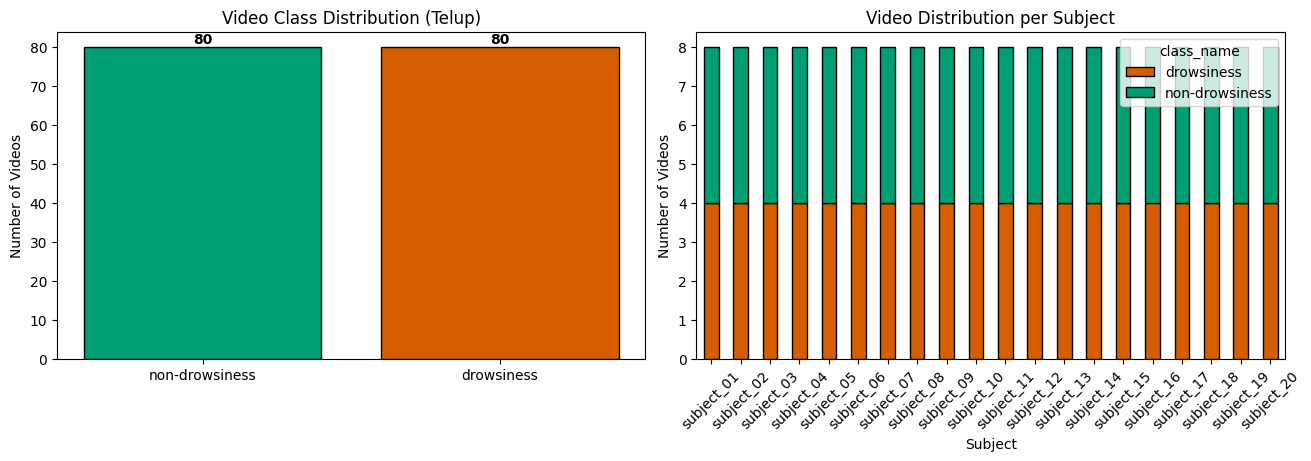

In [4]:
# Memindai video dan menampilkan jumlah serta lima data pertama
df_videos = scan_telup_videos()
print(f'Total videos found: {len(df_videos)}')
display(df_videos.head())

# Visualisasi distribusi kelas dan jumlah video per subjek
if not df_videos.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')

    # Distribusi jumlah video berdasarkan kelas
    counts = df_videos['class_name'].value_counts()
    axes[0].bar(counts.index, counts.values, color=['#009E73', '#D55E00'], edgecolor='black')
    axes[0].set(title='Video Class Distribution (Telup)', ylabel='Number of Videos')

    # Menampilkan jumlah video pada setiap kelas
    for i, v in enumerate(counts.values):
        axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

    # Distribusi video berdasarkan subjek dan kelas
    subj_counts = df_videos.groupby(['subject', 'class_name']).size().unstack(fill_value=0)
    subj_counts.plot(kind='bar', stacked=True, ax=axes[1],
                     color={'non-drowsiness': '#009E73', 'drowsiness': '#D55E00'},
                     edgecolor='black')
    axes[1].set(title='Video Distribution per Subject', xlabel='Subject', ylabel='Number of Videos')
    axes[1].tick_params(axis='x', rotation=45)

    # Menyimpan dan menampilkan hasil visualisasi
    fig.savefig(CONFIG.figures_dir / 'eda' / 'eda_class_subject_distribution.png', dpi=180)
    plt.show()
    plt.close(fig)

## 2. Preprocessing & Caching (Track A Points + Track B Face-Cropped 120-Frame Clips)


[SKIP] Track A features already cached (160 .pkl files).
[SKIP] Track B face clips already cached (160 .npy files).
Track A -> Train: 120 | Hold-out Test: 40
Track B -> Train: 120 | Hold-out Test: 40


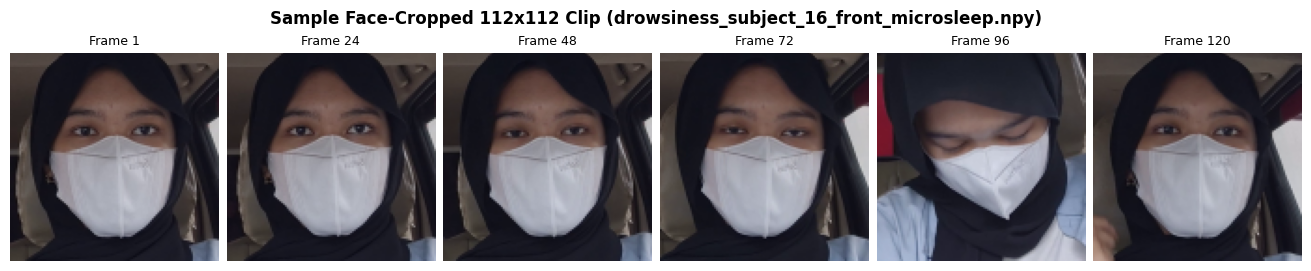

In [5]:
# Mengekstraksi dan menyimpan cache fitur landmark serta klip piksel
extract_point_features_cache(df_videos)
extract_pixel_clips_cache(df_videos)

# Membentuk DataFrame dan membagi data berdasarkan subjek
df_pt = build_point_feature_df()
df_px = build_pixel_clip_df()
df_pt_train, df_pt_test = split_subject_independent(df_pt)
df_px_train, df_px_test = split_subject_independent(df_px)

# Menampilkan jumlah data latih dan pengujian pada setiap track
print(f'Track A -> Train: {len(df_pt_train)} | Hold-out Test: {len(df_pt_test)}')
print(f'Track B -> Train: {len(df_px_train)} | Hold-out Test: {len(df_px_test)}')

# Visualisasi sampel frame dari klip wajah yang telah dipotong
if len(df_px_test) > 0:
    sample_clip = np.load(df_px_test.iloc[0]['path'])
    fig, axes = plt.subplots(1, 6, figsize=(13, 2.6), layout='constrained')

    # Menampilkan enam frame yang tersebar sepanjang klip
    for ax, f_idx in zip(axes, np.linspace(0, CONFIG.seq_len - 1, 6, dtype=int)):
        ax.imshow(sample_clip[f_idx])
        ax.set_title(f'Frame {f_idx + 1}', fontsize=9)
        ax.axis('off')

    # Menyimpan dan menampilkan hasil visualisasi
    fig.suptitle(f"Sample Face-Cropped 112x112 Clip ({df_px_test.iloc[0]['filename']})", fontweight='bold')
    fig.savefig(CONFIG.figures_dir / 'eda' / 'eda_pixel_face_crop_samples.png', dpi=180)
    plt.show()
    plt.close(fig)

## 3. Single-Model Experiment Runner (Safe Incremental Execution)


In [6]:
# Daftar model pada Track A (berbasis fitur landmark) dan Track B (berbasis citra)
TRACK_A_MODELS = {'RNN', 'CNN', 'LSTM', 'TRANSFORMER TEACHER', 'TRANSFORMER STUDENT', 'TRANSFORMER KD', 'TRANSFORMER KD+QAT'}
TRACK_B_MODELS = {'3D ResNet', '3D WideResNet', '3D ResNeXt', '3D DenseNet'}

# Fungsi untuk menjalankan satu model berdasarkan nama yang dipilih
def run_single_model(model_name: str, show_plot: bool = True):

    # Menentukan track, dataset, dan konfigurasi model
    if model_name in TRACK_A_MODELS:
        track = 'A'
        df_tr, df_te = df_pt_train, df_pt_test
        model_fn = lambda: build_point_model(model_name)
        use_kd = model_name in {'TRANSFORMER KD', 'TRANSFORMER KD+QAT'}
        teacher_fn = (lambda: build_point_model('TRANSFORMER TEACHER')) if use_kd else None
        teacher_name = 'TRANSFORMER TEACHER' if use_kd else None
        in_shape = (1, CONFIG.seq_len, CONFIG.point_input_dim)
        is_qat = 'QAT' in model_name

    elif model_name in TRACK_B_MODELS:
        track = 'B'
        df_tr, df_te = df_px_train, df_px_test
        model_fn = lambda: build_pixel_model(model_name)
        teacher_fn, teacher_name = None, None
        in_shape = (1, 3, CONFIG.seq_len, CONFIG.sample_size, CONFIG.sample_size)
        is_qat = False

    else:
        # Menolak nama model yang tidak terdaftar
        raise ValueError(f'Unknown model: {model_name}')

    # Menjalankan cross-validation dan evaluasi hold-out test
    cv_res = run_cv_training(
        model_fn, model_name, track, df_tr,
        teacher_fn, teacher_name, show_plot=show_plot
    )
    cv_res = evaluate_holdout_ensemble(model_fn, cv_res, df_te, track)

    # Mengukur efisiensi model berdasarkan jumlah parameter dan GFLOPs
    eff = profile_model(model_fn(), in_shape, model_name, is_int8_qat=is_qat)

    # Menyimpan hasil evaluasi dan profiling model
    out_json = save_per_model_result(cv_res, eff)
    print(f'[SAVED] {out_json} | GFLOPs: {eff["GFLOPs"]} | Params: {eff["Total_Params"]:,}')

    return cv_res, eff

## 4. Track A — Point / Landmark Models (Run Individually)



  5-FOLD GROUP-CV [Track A] : RNN
  Fold 1 -> Val Loss: 0.5285 | Acc: 70.83% | F1: 69.57%
  Fold 2 -> Val Loss: 0.6475 | Acc: 66.67% | F1: 66.67%
  Fold 3 -> Val Loss: 0.6492 | Acc: 66.67% | F1: 69.23%
  Fold 4 -> Val Loss: 0.5680 | Acc: 70.83% | F1: 66.67%
  Fold 5 -> Val Loss: 0.6122 | Acc: 58.33% | F1: 50.00%

  [CV Summary] RNN | Acc: 66.67% ± 5.10% | F1: 64.43% ± 8.18%


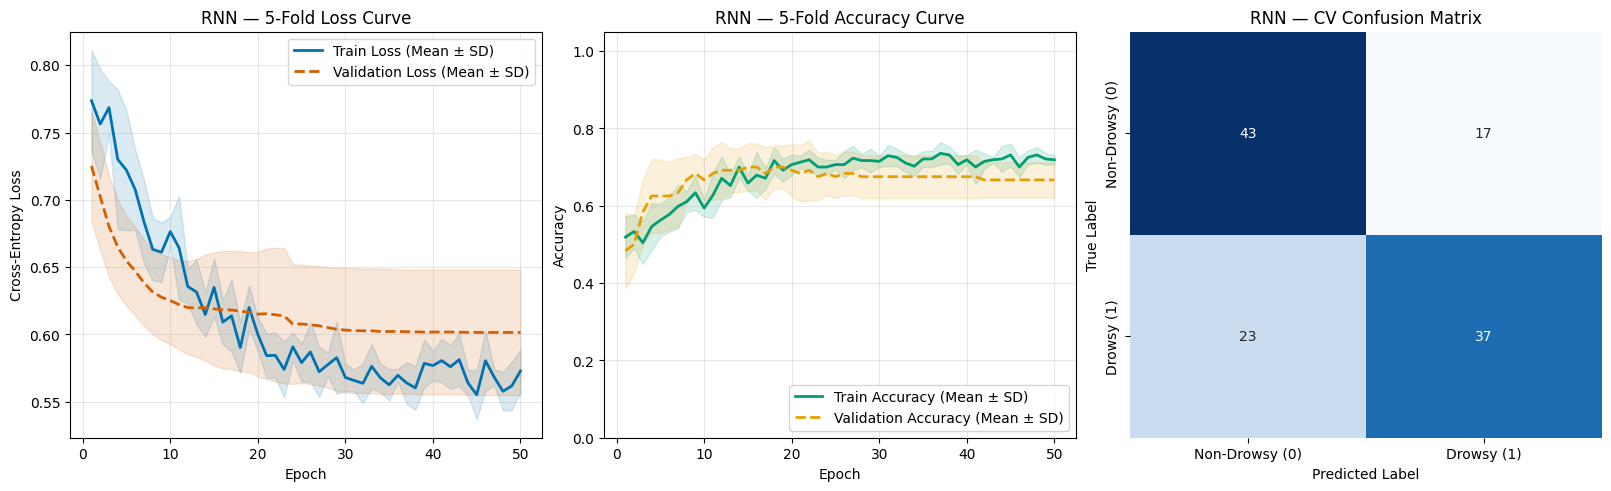

  [Hold-Out Test] RNN -> Acc: 72.50% | Prec: 76.47% | Rec: 65.00% | F1: 70.27%
[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\RNN.json | GFLOPs: 0.004332 | Params: 9,410


({'track': 'Track A',
  'model': 'RNN',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.5285370151201884,
    'accuracy': 0.7083333333333334,
    'precision': 0.7272727272727273,
    'recall': 0.6666666666666666,
    'f1': 0.6956521739130435,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\RNN_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.6475393573443095,
    'accuracy': 0.6666666666666666,
    'precision': 0.6666666666666666,
    'recall': 0.6666666666666666,
    'f1': 0.6666666666666666,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\RNN_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6491955320040385,
    'accuracy': 0.6666666666666666,
    'precision': 0.6428571428571429,
    'recall': 0.75,
    'f1': 0.6923076923076923,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\RNN_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.5680366555849711,
    'accuracy': 0.7

In [6]:
run_single_model('RNN')



  5-FOLD GROUP-CV [Track A] : CNN
  Fold 1 -> Val Loss: 0.5481 | Acc: 79.17% | F1: 80.00%
  Fold 2 -> Val Loss: 0.5881 | Acc: 70.83% | F1: 75.86%
  Fold 3 -> Val Loss: 0.6649 | Acc: 75.00% | F1: 75.00%
  Fold 4 -> Val Loss: 0.5269 | Acc: 75.00% | F1: 72.73%
  Fold 5 -> Val Loss: 0.5119 | Acc: 75.00% | F1: 72.73%

  [CV Summary] CNN | Acc: 75.00% ± 2.95% | F1: 75.26% ± 2.99%


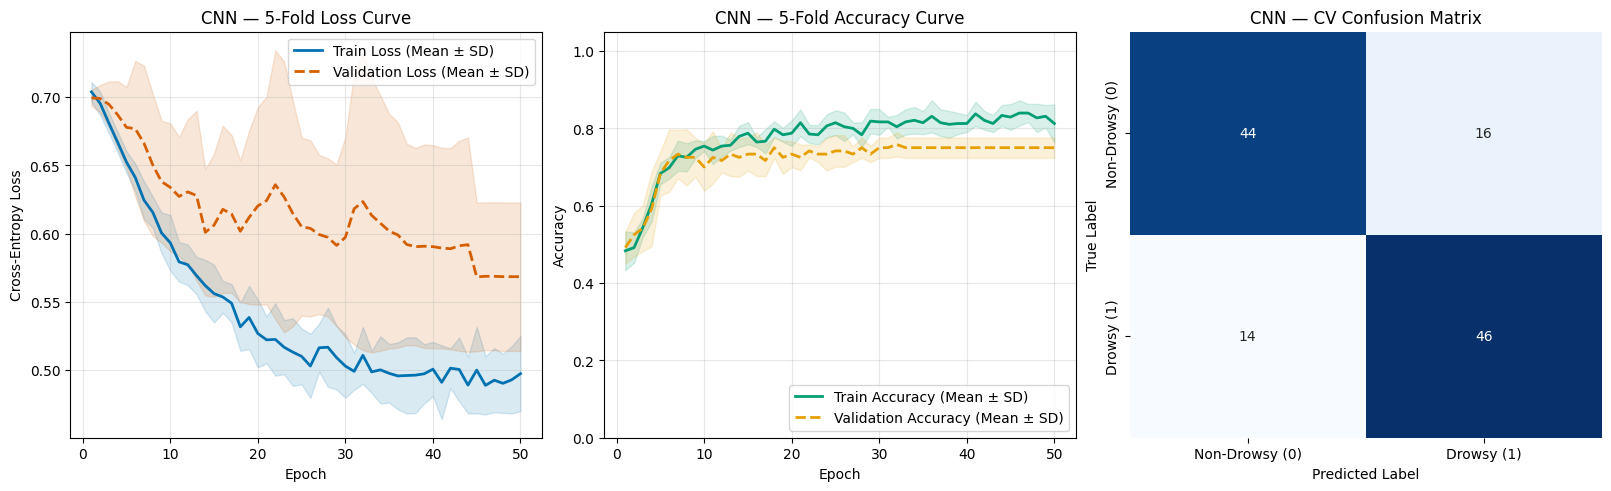

  [Hold-Out Test] CNN -> Acc: 82.50% | Prec: 80.95% | Rec: 85.00% | F1: 82.93%
[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\CNN.json | GFLOPs: 0.004923 | Params: 20,770


({'track': 'Track A',
  'model': 'CNN',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.5481486320495605,
    'accuracy': 0.7916666666666666,
    'precision': 0.7692307692307693,
    'recall': 0.8333333333333334,
    'f1': 0.8,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\CNN_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.5881154338518778,
    'accuracy': 0.7083333333333334,
    'precision': 0.6470588235294118,
    'recall': 0.9166666666666666,
    'f1': 0.7586206896551724,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\CNN_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6648752291997274,
    'accuracy': 0.75,
    'precision': 0.75,
    'recall': 0.75,
    'f1': 0.75,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\CNN_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.5269012649854025,
    'accuracy': 0.75,
    'precision': 0.8,
    'recall': 0.6666666666666666

In [7]:
run_single_model('CNN')



  5-FOLD GROUP-CV [Track A] : LSTM
  Fold 1 -> Val Loss: 0.5320 | Acc: 87.50% | F1: 88.00%
  Fold 2 -> Val Loss: 0.6694 | Acc: 75.00% | F1: 78.57%
  Fold 3 -> Val Loss: 0.6737 | Acc: 62.50% | F1: 64.00%
  Fold 4 -> Val Loss: 0.5228 | Acc: 83.33% | F1: 83.33%
  Fold 5 -> Val Loss: 0.5225 | Acc: 83.33% | F1: 81.82%

  [CV Summary] LSTM | Acc: 78.33% ± 9.95% | F1: 79.14% ± 9.12%


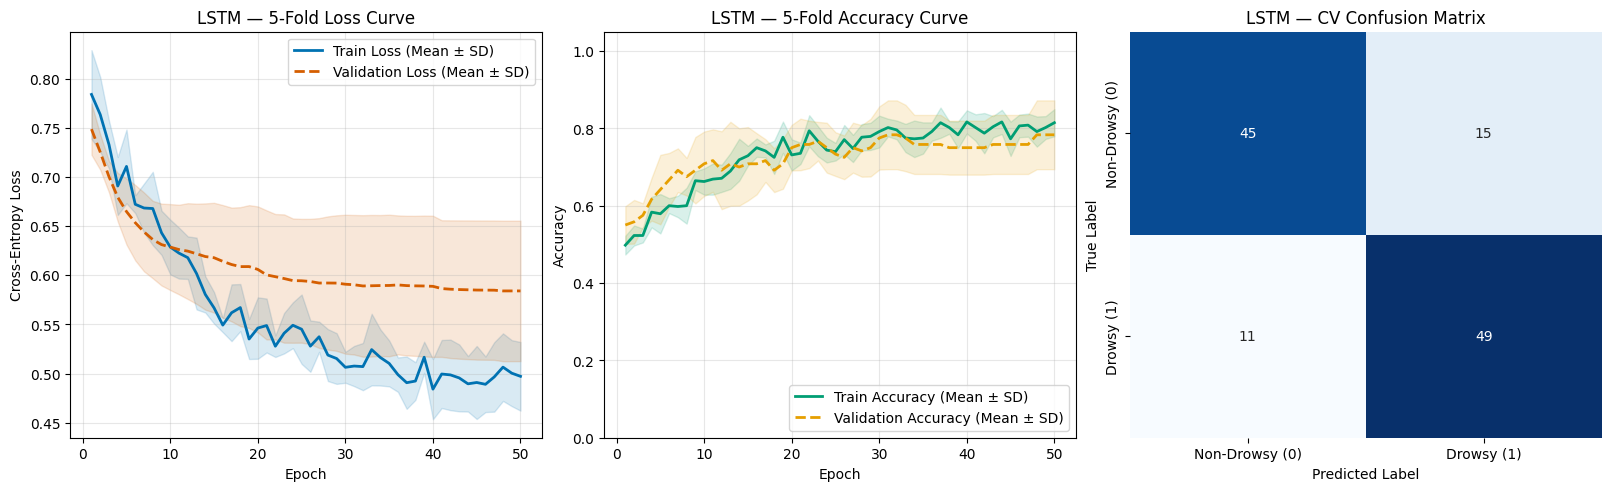

  [Hold-Out Test] LSTM -> Acc: 80.00% | Prec: 83.33% | Rec: 75.00% | F1: 78.95%
[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\LSTM.json | GFLOPs: 0.008663 | Params: 36,866


({'track': 'Track A',
  'model': 'LSTM',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.5320038696130117,
    'accuracy': 0.875,
    'precision': 0.8461538461538461,
    'recall': 0.9166666666666666,
    'f1': 0.88,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\LSTM_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.6694004734357198,
    'accuracy': 0.75,
    'precision': 0.6875,
    'recall': 0.9166666666666666,
    'f1': 0.7857142857142857,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\LSTM_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6736563444137573,
    'accuracy': 0.625,
    'precision': 0.6153846153846154,
    'recall': 0.6666666666666666,
    'f1': 0.64,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\LSTM_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.5228368639945984,
    'accuracy': 0.8333333333333334,
    'precision': 0.8333333333333334,
    'rec

In [8]:
run_single_model('LSTM')



  5-FOLD GROUP-CV [Track A] : TRANSFORMER TEACHER


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 1 -> Val Loss: 0.5486 | Acc: 83.33% | F1: 84.62%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 2 -> Val Loss: 0.6376 | Acc: 70.83% | F1: 72.00%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 3 -> Val Loss: 0.6342 | Acc: 62.50% | F1: 60.87%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 4 -> Val Loss: 0.4788 | Acc: 79.17% | F1: 78.26%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 5 -> Val Loss: 0.6092 | Acc: 70.83% | F1: 69.57%

  [CV Summary] TRANSFORMER TEACHER | Acc: 73.33% ± 8.12% | F1: 73.06% ± 8.98%


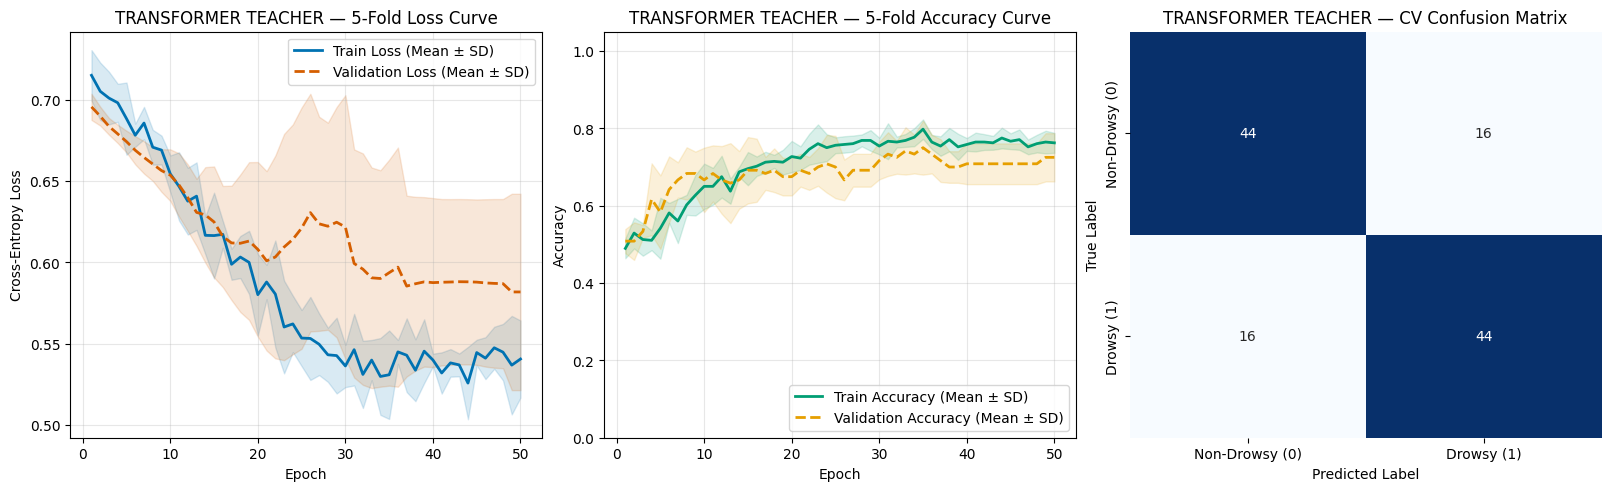

c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  [Hold-Out Test] TRANSFORMER TEACHER -> Acc: 80.00% | Prec: 80.00% | Rec: 80.00% | F1: 80.00%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\TRANSFORMER_TEACHER.json | GFLOPs: 0.000839 | Params: 42,914


({'track': 'Track A',
  'model': 'TRANSFORMER TEACHER',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.5485559701919556,
    'accuracy': 0.8333333333333334,
    'precision': 0.7857142857142857,
    'recall': 0.9166666666666666,
    'f1': 0.8461538461538461,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_TEACHER_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.6376162568728129,
    'accuracy': 0.7083333333333334,
    'precision': 0.6923076923076923,
    'recall': 0.75,
    'f1': 0.72,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_TEACHER_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6341975927352905,
    'accuracy': 0.625,
    'precision': 0.6363636363636364,
    'recall': 0.5833333333333334,
    'f1': 0.6086956521739131,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_TEACHER_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.

In [9]:
run_single_model('TRANSFORMER TEACHER')



  5-FOLD GROUP-CV [Track A] : TRANSFORMER STUDENT


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 1 -> Val Loss: 0.6369 | Acc: 62.50% | F1: 64.00%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 2 -> Val Loss: 0.6264 | Acc: 62.50% | F1: 66.67%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 3 -> Val Loss: 0.6819 | Acc: 50.00% | F1: 53.85%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 4 -> Val Loss: 0.6103 | Acc: 83.33% | F1: 83.33%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 5 -> Val Loss: 0.6833 | Acc: 54.17% | F1: 35.29%

  [CV Summary] TRANSFORMER STUDENT | Acc: 62.50% ± 12.84% | F1: 60.63% ± 17.69%


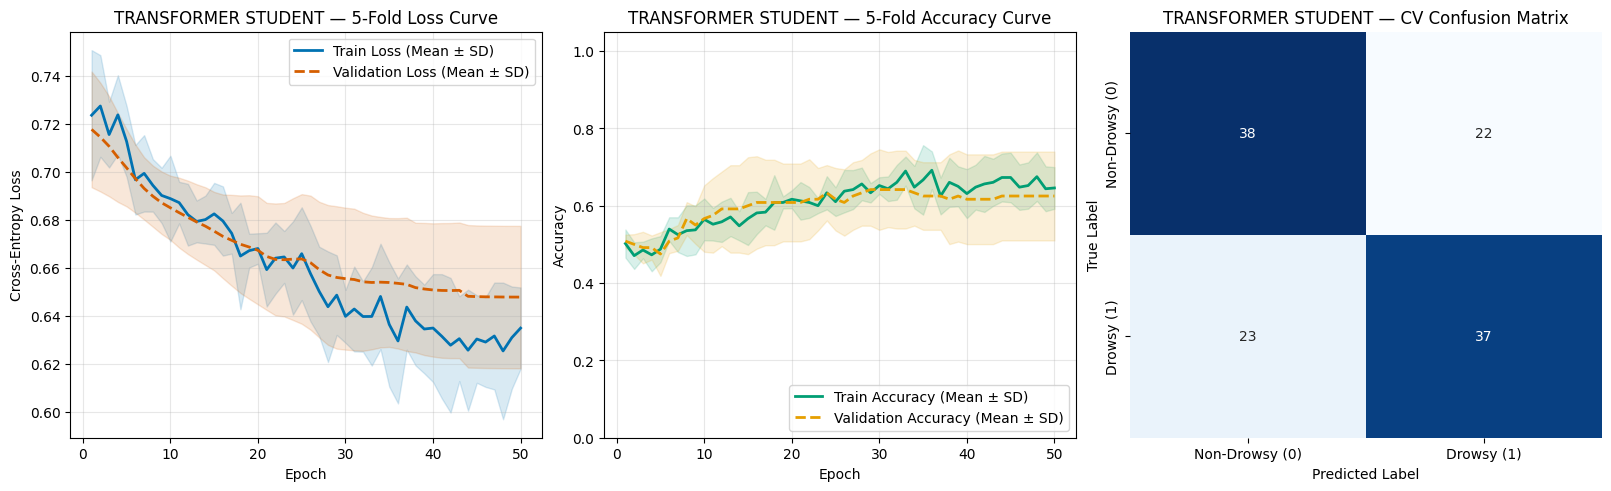

c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  [Hold-Out Test] TRANSFORMER STUDENT -> Acc: 75.00% | Prec: 75.00% | Rec: 75.00% | F1: 75.00%
[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\TRANSFORMER_STUDENT.json | GFLOPs: 0.000419 | Params: 8,706


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


({'track': 'Track A',
  'model': 'TRANSFORMER STUDENT',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.6368616223335266,
    'accuracy': 0.625,
    'precision': 0.6153846153846154,
    'recall': 0.6666666666666666,
    'f1': 0.64,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_STUDENT_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.6263691981633505,
    'accuracy': 0.625,
    'precision': 0.6,
    'recall': 0.75,
    'f1': 0.6666666666666666,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_STUDENT_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6818809906641642,
    'accuracy': 0.5,
    'precision': 0.5,
    'recall': 0.5833333333333334,
    'f1': 0.5384615384615384,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_STUDENT_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.6103346347808838,
    'accuracy': 0.8333333333333334,
    

In [10]:
run_single_model('TRANSFORMER STUDENT')



  5-FOLD GROUP-CV [Track A] : TRANSFORMER KD


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 1 -> Val Loss: 0.6068 | Acc: 66.67% | F1: 69.23%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 2 -> Val Loss: 0.6312 | Acc: 70.83% | F1: 77.42%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 3 -> Val Loss: 0.6803 | Acc: 54.17% | F1: 59.26%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 4 -> Val Loss: 0.5275 | Acc: 83.33% | F1: 83.33%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 5 -> Val Loss: 0.6799 | Acc: 54.17% | F1: 35.29%

  [CV Summary] TRANSFORMER KD | Acc: 65.83% ± 12.29% | F1: 64.91% ± 18.87%


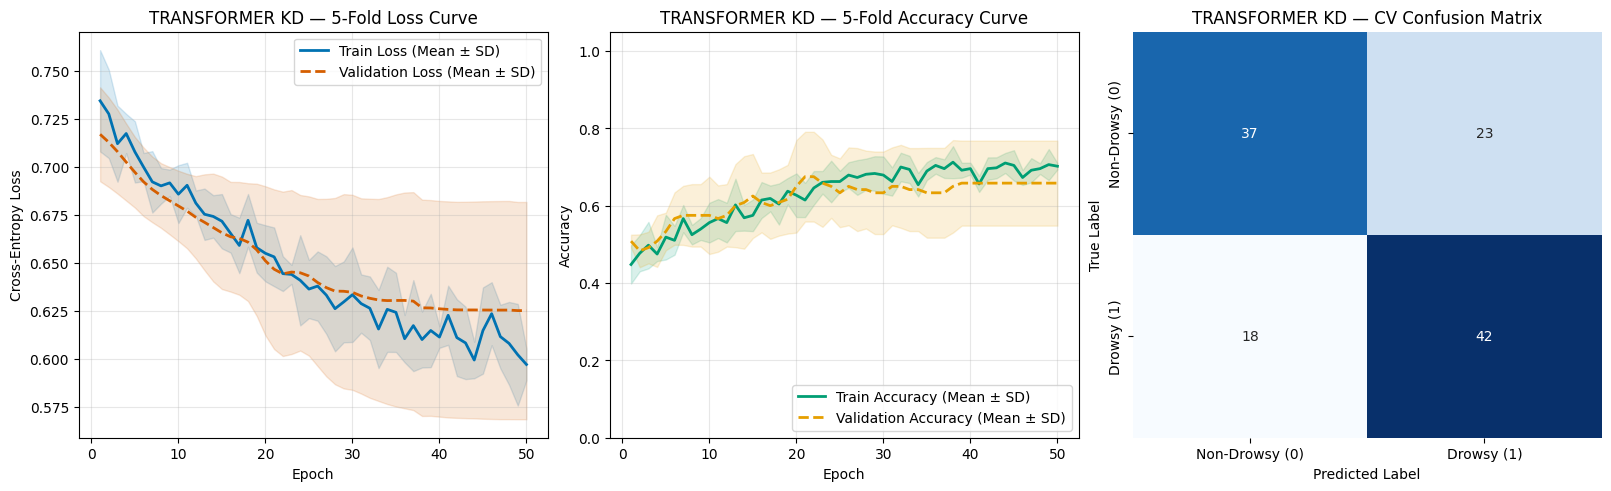

c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  [Hold-Out Test] TRANSFORMER KD -> Acc: 77.50% | Prec: 76.19% | Rec: 80.00% | F1: 78.05%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\TRANSFORMER_KD.json | GFLOPs: 0.000419 | Params: 8,706


({'track': 'Track A',
  'model': 'TRANSFORMER KD',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.6068321069081625,
    'accuracy': 0.6666666666666666,
    'precision': 0.6428571428571429,
    'recall': 0.75,
    'f1': 0.6923076923076923,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.631160040696462,
    'accuracy': 0.7083333333333334,
    'precision': 0.631578947368421,
    'recall': 1.0,
    'f1': 0.7741935483870968,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6802942355473837,
    'accuracy': 0.5416666666666666,
    'precision': 0.5333333333333333,
    'recall': 0.6666666666666666,
    'f1': 0.5925925925925926,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_fold3_best.pth'},
   {'fold': 4,
    'val_loss': 0.5274771451

In [11]:
run_single_model('TRANSFORMER KD')



  5-FOLD GROUP-CV [Track A] : TRANSFORMER KD+QAT


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 1 -> Val Loss: 0.6071 | Acc: 66.67% | F1: 69.23%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 2 -> Val Loss: 0.6323 | Acc: 70.83% | F1: 77.42%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 3 -> Val Loss: 0.6805 | Acc: 54.17% | F1: 59.26%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 4 -> Val Loss: 0.5282 | Acc: 83.33% | F1: 83.33%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  Fold 5 -> Val Loss: 0.6808 | Acc: 54.17% | F1: 35.29%

  [CV Summary] TRANSFORMER KD+QAT | Acc: 65.83% ± 12.29% | F1: 64.91% ± 18.87%


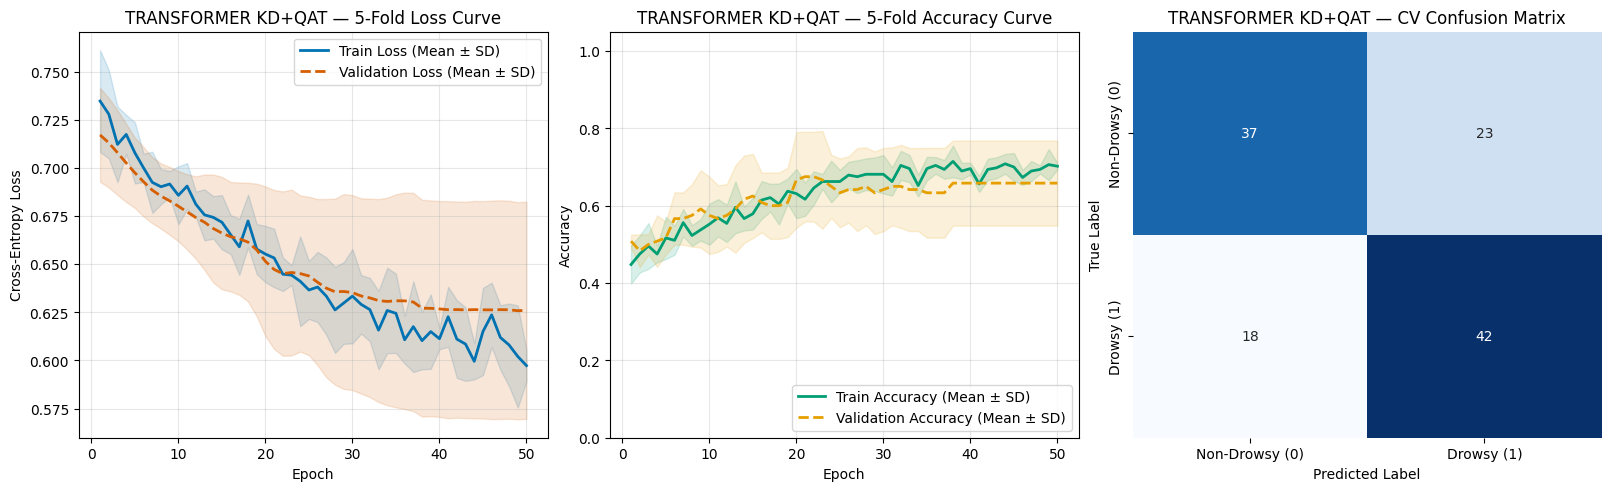

c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


  [Hold-Out Test] TRANSFORMER KD+QAT -> Acc: 77.50% | Prec: 76.19% | Rec: 80.00% | F1: 78.05%


c:\Users\User\tugas akhir\src\models_point.py:139: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


[SAVED] C:\Users\User\tugas akhir\results\telup\tables\per_model\TRANSFORMER_KD_QAT.json | GFLOPs: 0.000419 | Params: 8,706


({'track': 'Track A',
  'model': 'TRANSFORMER KD+QAT',
  'fold_metrics': [{'fold': 1,
    'val_loss': 0.6071444948514303,
    'accuracy': 0.6666666666666666,
    'precision': 0.6428571428571429,
    'recall': 0.75,
    'f1': 0.6923076923076923,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_QAT_fold1_best.pth'},
   {'fold': 2,
    'val_loss': 0.6322707931200663,
    'accuracy': 0.7083333333333334,
    'precision': 0.631578947368421,
    'recall': 1.0,
    'f1': 0.7741935483870968,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_QAT_fold2_best.pth'},
   {'fold': 3,
    'val_loss': 0.6804962555567423,
    'accuracy': 0.5416666666666666,
    'precision': 0.5333333333333333,
    'recall': 0.6666666666666666,
    'f1': 0.5925925925925926,
    'ckpt_path': 'C:\\Users\\User\\tugas akhir\\results\\telup\\checkpoints\\track_a\\TRANSFORMER_KD_QAT_fold3_best.pth'},
   {'fold': 4,
    'val_lo

In [12]:
run_single_model('TRANSFORMER KD+QAT')


## 5. Track B — Pixel / 3D CNN Models (Run Individually)


In [ ]:
run_single_model('3D ResNet')


In [ ]:
run_single_model('3D WideResNet')


In [ ]:
run_single_model('3D ResNeXt')


In [ ]:
run_single_model('3D DenseNet')


## 6. Compile All Saved Results & Overall Comparison Charts


,Track,Model,Total_Params,Trainable_Params,GFLOPs,Size_KB,Latency_ms,CV_Val_Loss,CV_Acc (%),CV_Acc_SD (%),CV_F1 (%),CV_F1_SD (%),Test_Acc (%),Test_Prec (%),Test_Rec (%),Test_F1 (%)
0,Track B,3D ResNet,33031106,24777730,124.837431,129027.76,86.367,0.6081,76.67,11.26,76.05,11.52,85.0,93.75,75.0,83.33
1,Track B,3D ResNeXt,47525314,16318466,143.747244,185645.76,106.383,0.5680,75.83,6.18,74.35,6.11,80.0,77.27,85.0,80.95
2,Track B,3D WideResNet,157432770,98598914,395.142963,614971.76,202.500,0.5413,76.67,4.75,77.49,5.45,92.5,90.48,95.0,92.68
3,Track A,CNN,20770,20770,0.004923,81.13,0.917,0.5680,75.00,2.95,75.26,2.99,82.5,80.95,85.0,82.93
4,Track A,LSTM,36866,36866,0.008663,144.01,1.371,0.5841,78.33,9.95,79.14,9.12,80.0,83.33,75.0,78.95
5,Track A,RNN,9410,9410,0.004332,36.76,16.405,0.6011,66.67,5.10,64.43,8.18,72.5,76.47,65.0,70.27
6,Track A,TRANSFORMER KD,8706,8706,0.000419,34.01,3.118,0.6251,65.83,12.29,64.91,18.87,77.5,76.19,80.0,78.05
7,Track A,TRANSFORMER KD+QAT,8706,8706,0.000419,8.50,6.052,0.6258,65.83,12.29,64.91,18.87,77.5,76.19,80.0,78.05
8,Track A,TRANSFORMER STUDENT,8706,8706,0.000419,34.01,2.126,0.6478,62.50,12.84,60.63,17.69,75.0,75.00,75.0,75.00
9,Track A,TRANSFORMER TEACHER,42914,42914,0.000839,167.63,2.755,0.5817,73.33,8.12,73.06,8.98,80.0,80.00,80.0,80.00


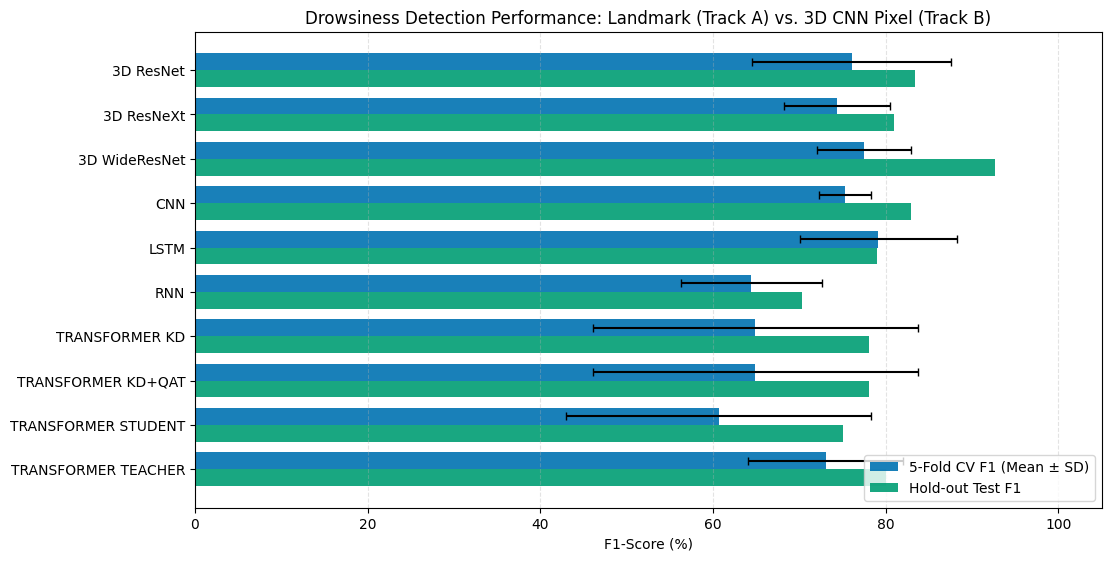

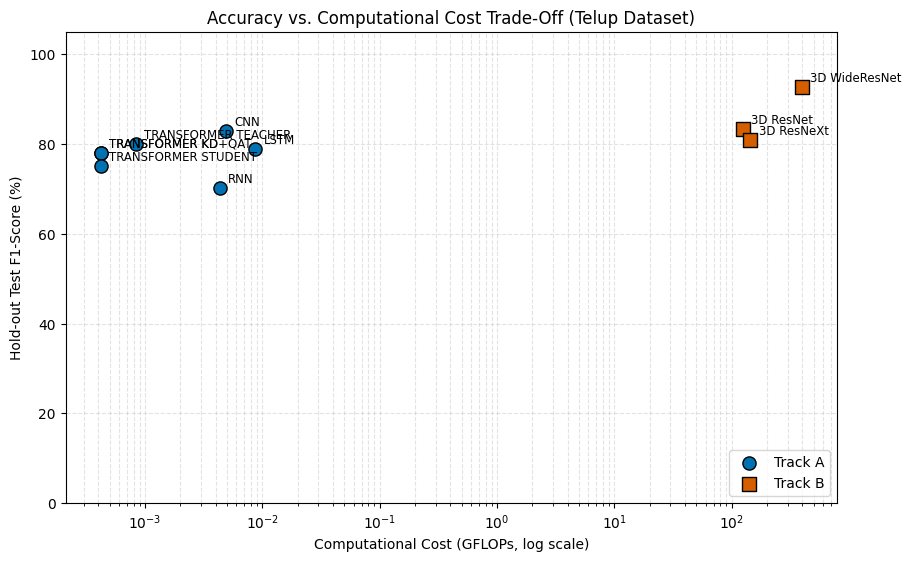

In [7]:
# Menggabungkan seluruh hasil evaluasi model dan cross-validation
df_summary, df_folds = compile_all_saved_results()

# Menampilkan ringkasan hasil evaluasi seluruh model
display(df_summary)

# Membuat visualisasi perbandingan performa seluruh model
plot_overall_comparison(df_summary)

## 7. Explainable AI (XAI): SHAP (Track A) & Top-K 3D Score-CAM (Track B)


In [19]:
import importlib, src.xai
importlib.reload(src.xai)
from src.xai import run_shap_analysis

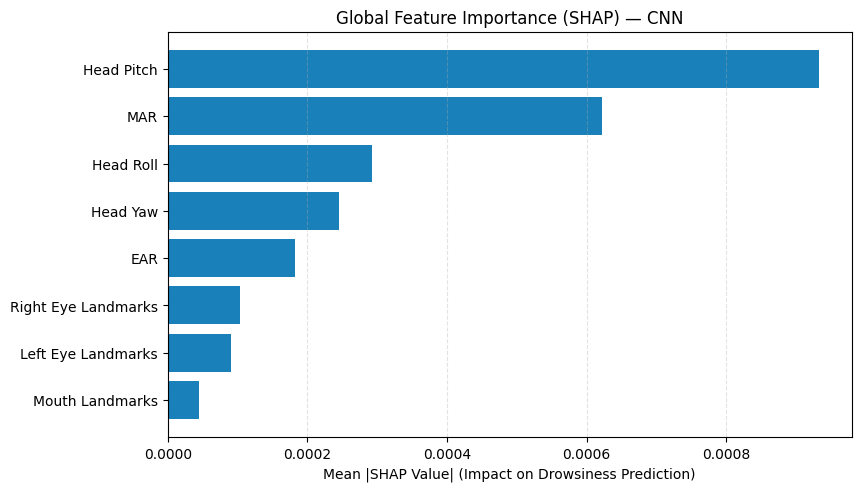

c:\Users\User\tugas akhir\src\xai.py:97: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  temp_imp = (temp_imp - temp_imp.min()) / (temp_imp.max() - temp_imp.min() + 1e-6)


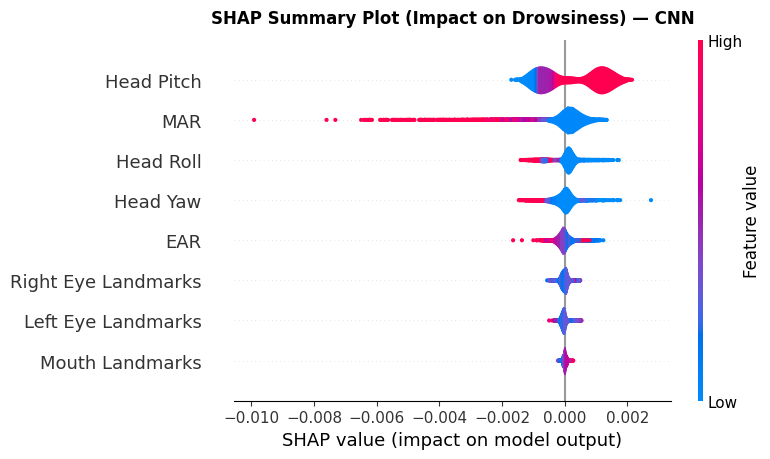

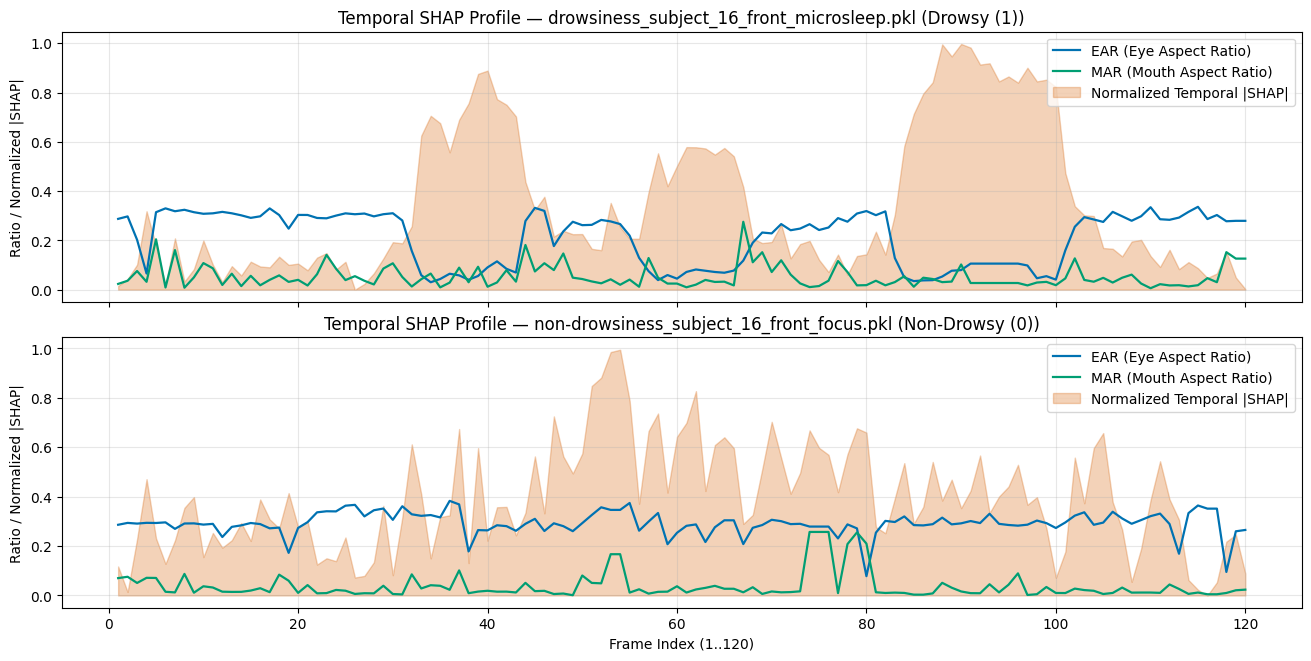

,Feature_Group,Mean_Abs_SHAP
0,Head Pitch,0.000933
1,MAR,0.000622
2,Head Roll,0.000293
3,Head Yaw,0.000246
4,EAR,0.000182
5,Right Eye Landmarks,0.000104
6,Left Eye Landmarks,0.000090
7,Mouth Landmarks,0.000045


In [20]:
# Track A XAI — SHAP Value (using best fold checkpoint of TRANSFORMER KD+QAT or any Track A model)
shap_model_name = 'CNN'
shap_ckpt = CONFIG.ckpt_track_a_dir / f'{_safe_slug(shap_model_name)}_fold1_best.pth'
if shap_ckpt.exists():
    df_shap = run_shap_analysis(lambda: build_point_model(shap_model_name), str(shap_ckpt), shap_model_name, df_pt_train, df_pt_test)
    display(df_shap)
else:
    print(f'Train {shap_model_name} first to run SHAP analysis.')

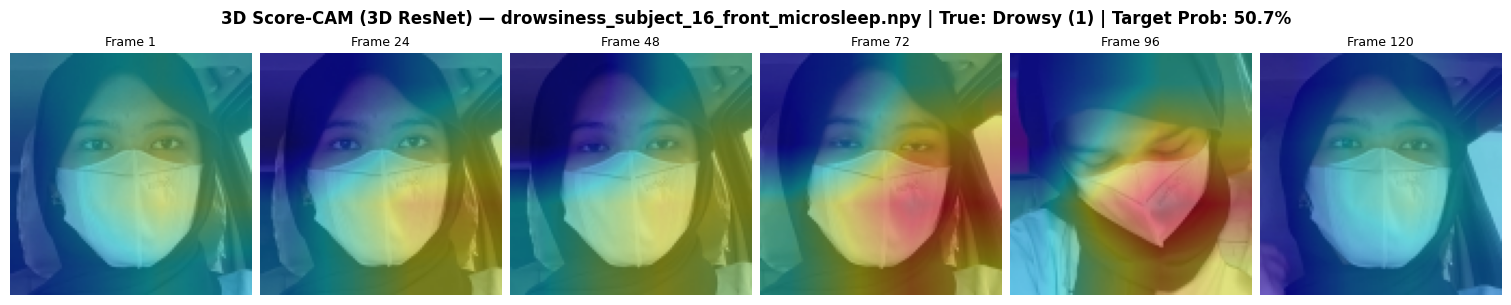

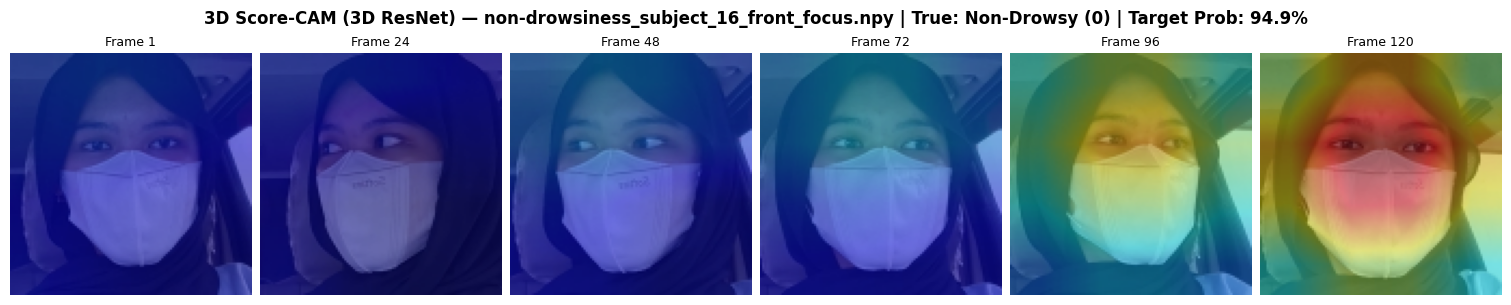

In [9]:
# Track B XAI — Top-K 3D Score-CAM (e.g., on 3D ResNet)
cam_model_name = '3D ResNet'
cam_ckpt = CONFIG.ckpt_track_b_dir / f'{_safe_slug(cam_model_name)}_fold1_best.pth'
if cam_ckpt.exists():
    visualize_scorecam_3d(lambda: build_pixel_model(cam_model_name, load_pretrained=False), str(cam_ckpt), cam_model_name, df_px_test)
else:
    print(f'Train {cam_model_name} first to run 3D Score-CAM.')